# Automate API Extraction

In [ ]:
from requests import Request, Session
from requests.exceptions import ConnectionError, Timeout, TooManyRedirects
import json
import pandas as pd

url = 'https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest' 
#Original Sandbox Environment: 'https://sandbox-api.coinmarketcap.com/v1/cryptocurrency/listings/latest'
parameters = {
  'start':'1',
  'limit':'10',
  'convert':'USD'
}
headers = {
  'Accepts': 'application/json',
  'X-CMC_PRO_API_KEY': "YOUR_API_KEY",
}

session = Session()
session.headers.update(headers)

try:
  response = session.get(url, params=parameters)
  data = json.loads(response.text)
  #print(data)
except (ConnectionError, Timeout, TooManyRedirects) as e:
  print(e)

In [19]:
type(data)

dict

In [50]:
#To see all the columns and rows
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)

In [21]:
#Normalize the data and make it all pretty in a dataframe

df = pd.json_normalize(data['data'])
df['timestamp'] = pd.to_datetime('now')
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20085856.000,20085856.000,21000000.000,2010-07-13T00:00:00.000Z,12751,1,2026-09-18T01:00:00.000Z,None,NaN,NaN,NaN,1537087247006.630,"[mineable, pow, sha-256, store-of-value, state...",76525.852,21573600881.254,21509448076.696,64152804.558,-28.672,0.229,0.313,-0.485,18.795,18.608,20.561,1537087247006.635,58.587,1607042895614.670,None,2026-09-18T01:00:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 20:02:30.239976
1,1027,Ethereum,ETH,ethereum,True,122056009.606,122056009.606,NaN,2015-08-07T00:00:00.000Z,13557,2,2026-09-18T01:01:00.000Z,None,NaN,NaN,NaN,298802129962.420,"[pos, smart-contracts, ethereum-ecosystem, coi...",2448.074,11473446424.841,11263459912.362,209986512.479,-27.532,0.120,1.368,-0.350,28.023,30.824,43.358,298802129962.422,11.384,298802129962.420,None,2026-09-18T01:01:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 20:02:30.239976
2,825,Tether USDt,USDT,tether,True,183442587855.580,189330914156.580,NaN,2015-02-25T00:00:00.000Z,200996,3,2026-09-18T01:00:00.000Z,None,NaN,NaN,NaN,189188498166.130,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.999,58978260066.978,57511692426.365,1466567640.613,-15.969,0.012,-0.004,-0.043,0.003,-0.001,0.016,183304601103.881,6.986,189188498166.130,None,2026-09-18T01:00:00.000Z,1027.000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-09-17 20:02:30.239976
3,1839,BNB,BNB,bnb,False,133160494.740,133160494.740,133160494.740,2017-07-25T00:00:00.000Z,3464,4,2026-09-18T01:00:00.000Z,None,NaN,NaN,NaN,98135504498.580,"[marketplace, centralized-exchange, payments, ...",736.972,1474167672.510,1448499722.352,25667950.158,-2.768,-0.139,1.754,3.364,22.136,29.493,26.941,98135504498.582,3.740,98135505530.340,None,2026-09-18T01:00:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 20:02:30.239976
4,52,XRP,XRP,xrp,False,62879209849.000,99985622230.000,100000000000.000,2013-08-04T00:00:00.000Z,1884,5,2026-09-18T01:01:00.000Z,None,NaN,NaN,NaN,129959369293.200,"[medium-of-exchange, enterprise-solutions, xrp...",1.300,2515319744.317,2513709597.925,1610146.392,-38.882,0.333,0.455,-3.080,30.492,18.633,14.319,81729175369.162,3.114,129978057239.320,None,2026-09-18T01:01:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 20:02:30.239976
5,3408,USDC,USDC,usd-coin,False,73898932235.573,73898932235.573,NaN,2018-10-08T00:00:00.000Z,45292,6,2026-09-18T01:00:00.000Z,None,NaN,60901219650.230,60896095045.573,73892713923.120,"[medium-of-exchange, stablecoin, asset-backed-...",1.000,13033467576.775,11232183556.760,1801284020.015,-26.938,0.010,0.002,0.003,0.005,0.007,0.018,73892713923.124,2.815,73892713923.120,None,2026-09-18T01:00:00.000Z,24091.000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-09-17 20:02:30.239976
6,5426,Solana,SOL,solana,True,587211660.564,634204087.873,NaN,2020-04-10T00:00:00.000Z,1179,7,2026-09-18T01:01:00.000Z,None,NaN,525236893.300,53248695509.733,64295826886.800,"[pos, platform, solana-ecosystem, cms-holdings...",101.380,3004805184.284,3004725146.852,80037.432,-5.130,-0.170,2.776,2.231,31.850,32.387,45.670,59531718567.324,2.268,64295826886.800,None,2026-09-18T01:01:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 20:02:30.239976
7,1958,TRON,TRX,tron,True,94954212160.598,94954200028.718,NaN,2017-09-13T00:00:00.000Z,1376,8,2026-09-18T01:01:00.000Z,None,NaN

### Automate

In [ ]:
def api_runner():
    global df
    
    url = 'https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest' 
    #Original Sandbox Environment: 'https://sandbox-api.coinmarketcap.com/v1/cryptocurrency/listings/latest'
    parameters = {
        'start':'1',
        'limit':'30',
        'convert':'USD'
    }
    headers = {
        'Accepts': 'application/json',
        'X-CMC_PRO_API_KEY': "YOUR_API_KEY",
     }

    session = Session()
    session.headers.update(headers)

    try:
        response = session.get(url, params=parameters)
        data = json.loads(response.text)
        #print(data)
    except (ConnectionError, Timeout, TooManyRedirects) as e:
        print(e)

    df = pd.json_normalize(data['data'])
    df['timestamp'] = pd.to_datetime('now')
    df

    #create a csv file and add data there
    if not os.path.isfile(r'C:\Users\path\to\Python Projects\Crypto Scraping\Crypto_API.csv'):
        df.to_csv(r'C:\Users\path\to\Python Projects\Crypto Scraping\Crypto_API.csv', header = 'column_names')
    else:
        df.to_csv(r'C:\Users\path\to\Python Projects\Crypto Scraping\Crypto_API.csv', mode = 'a', header = False)

In [ ]:
import os
from time import time
from time import sleep

for i in range(250): #250 max API requests, though another API might have another limit.
    api_runner()
    print('API runner completed successfully!')
    sleep(60) # sleep for 1 minute
exit()


API runner completed successfully!


KeyboardInterrupt: 

In [ ]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.008582e+07,2.008582e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12751,1,2026-09-17T21:51:00.000Z,None,NaN,NaN,NaN,1.534720e+12,"[mineable, pow, sha-256, store-of-value, state...",76408.147129,2.252716e+10,2.245947e+10,6.769131e+07,-26.3189,-0.058677,0.668244,-0.954945,18.340330,18.753818,21.172191,1.534720e+12,58.5490,1.604571e+12,None,2026-09-17T21:51:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 16:53:32.447588
1,1027,Ethereum,ETH,ethereum,True,1.220560e+08,1.220560e+08,NaN,2015-08-07T00:00:00.000Z,13553,2,2026-09-17T21:52:00.000Z,None,NaN,NaN,NaN,2.987126e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",2447.340541,1.203757e+10,1.183138e+10,2.061965e+08,-24.8524,-0.063970,1.962411,-0.488533,28.069071,31.607611,43.795398,2.987126e+11,11.4024,2.987126e+11,None,2026-09-17T21:52:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 16:53:32.447588
2,825,Tether USDt,USDT,tether,True,1.834426e+11,1.893309e+11,NaN,2015-02-25T00:00:00.000Z,200990,3,2026-09-17T21:51:00.000Z,None,NaN,NaN,NaN,1.891990e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.999303,6.092622e+10,5.939974e+10,1.526477e+09,-12.6547,0.012609,0.017078,-0.034723,0.006963,0.014202,0.026953,1.833148e+11,6.9953,1.891990e+11,None,2026-09-17T21:51:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-09-17 16:53:32.447588
3,1839,BNB,BNB,bnb,False,1.331605e+08,1.331605e+08,1.331605e+08,2017-07-25T00:00:00.000Z,3464,4,2026-09-17T21:51:00.000Z,None,NaN,NaN,NaN,9.769990e+10,"[marketplace, centralized-exchange, payments, ...",733.700295,1.475027e+09,1.448361e+09,2.666618e+07,0.1722,0.020306,1.935674,2.713140,21.838546,29.097511,26.501616,9.769990e+10,3.7272,9.769990e+10,None,2026-09-17T21:51:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 16:53:32.447588
4,52,XRP,XRP,xrp,False,6.287921e+10,9.998562e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1884,5,2026-09-17T21:51:00.000Z,None,NaN,NaN,NaN,1.293323e+11,"[medium-of-exchange, enterprise-solutions, xrp...",1.293509,2.630875e+09,2.629179e+09,1.696315e+06,-37.9509,-0.153941,0.461963,-4.458452,29.334636,18.458005,14.470854,8.133481e+10,3.1047,1.293509e+11,None,2026-09-17T21:51:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 16:53:32.447588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,3408,USDC,USDC,usd-coin,False,7.389409e+10,7.389409e+10,NaN,2018-10-08T00:00:00.000Z,45285,6,2026-09-17T22:36:00.000Z,None,NaN,6.090122e+10,6.089231e+10,7.388329e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999854,1.333662e+10,1.151482e+10,1.821798e+09,-24.8883,0.006598,-0.001608,-0.006108,0.000889,0.000959,0.009990,7.388329e+10,2.8264,7.388329e+10,None,2026-09-17T22:36:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-09-17 17:37:16.040548
316,5426,Solana,SOL,solana,True,5.872118e+08,6.342042e+08,NaN,2020-04-10T00:00:00.000Z,1179,7,2026-09-17T22:36:00.000Z,None,NaN,5.252369e+08,5.303643e+10,6.403954e+10,"[pos, platform, solana-ecosystem, cms-holdings...",100.976212,2.964465e+09,2.964385e+09,7.979084e+04,-6.7109,-0.253874,3.449423,1.486734,30.991782,32.703131,45.781609,5.929442e+10,2.2676,6.403954e+10,None,2026-09-17T22:36:00.000Z,NaN

In [ ]:
df2 = pd.read_csv(r'C:\Users\path\to\Python Projects\Crypto Scraping\Crypto_API.csv')
df2

,Unnamed: 0,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,0,1,Bitcoin,BTC,bitcoin,False,20085834.000,20085834.000,21000000.000,2010-07-13T00:00:00.000Z,12751,1,2026-09-17T22:50:00.000Z,NaN,NaN,NaN,NaN,1533663684642.060,"['mineable', 'pow', 'sha-256', 'store-of-value...",76355.489,22352031801.843,22284548433.714,67483368.129,-25.293,-0.090,0.906,-0.751,18.224,18.062,20.651,1533663684642.062,58.556,1603465276945.100,NaN,2026-09-17T22:50:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 17:51:53.614323
1,1,1027,Ethereum,ETH,ethereum,True,122056009.606,122056009.606,NaN,2015-08-07T00:00:00.000Z,13554,2,2026-09-17T22:51:00.000Z,NaN,NaN,NaN,NaN,298242561075.640,"['pos', 'smart-contracts', 'ethereum-ecosystem...",2443.489,11983179956.087,11762036633.128,221143322.958,-23.991,-0.175,2.179,-0.225,27.765,30.706,43.160,298242561075.637,11.387,298242561075.640,NaN,2026-09-17T22:51:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 17:51:53.614323
2,2,825,Tether USDt,USDT,tether,True,183442587855.580,189330914156.580,NaN,2015-02-25T00:00:00.000Z,200991,3,2026-09-17T22:50:00.000Z,NaN,NaN,NaN,NaN,189177392212.090,"['stablecoin', 'asset-backed-stablecoin', 'usd...",0.999,59963596683.739,58448038231.221,1515558452.517,-13.419,-0.008,-0.009,-0.039,-0.012,-0.021,-0.001,183293840552.921,6.998,189177392212.090,NaN,2026-09-17T22:50:00.000Z,1027.000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-09-17 17:51:53.614323
3,3,1839,BNB,BNB,bnb,False,133160501.430,133160501.430,133160501.430,2017-07-25T00:00:00.000Z,3464,4,2026-09-17T22:50:00.000Z,NaN,NaN,NaN,NaN,97825027857.770,"['marketplace', 'centralized-exchange', 'payme...",734.640,1482854541.327,1456406816.263,26447725.064,1.593,0.129,2.197,3.105,21.878,28.751,26.547,97825027857.771,3.735,97825027857.770,NaN,2026-09-17T22:50:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 17:51:53.614323
4,4,52,XRP,XRP,xrp,False,62879209849.000,99985622230.000,100000000000.000,2013-08-04T00:00:00.000Z,1884,5,2026-09-17T22:51:00.000Z,NaN,NaN,NaN,NaN,129381228959.830,"['medium-of-exchange', 'enterprise-solutions',...",1.294,2626074498.541,2624324943.666,1749554.875,-37.378,0.038,0.567,-3.954,29.450,17.872,14.133,81365593020.689,3.107,129399833770.310,NaN,2026-09-17T22:51:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-17 17:51:53.614323
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1115,5,3408,USDC,USDC,usd-coin,False,73898932235.573,73898932235.573,NaN,2018-10-08T00:00:00.000Z,45292,6,2026-09-18T01:00:00.000Z,NaN,NaN,60901219650.230,60896095045.573,73892713923.120,"['medium-of-exchange', 'stablecoin', 'asset-ba...",1.000,13033467576.775,11232183556.760,1801284020.015,-26.938,0.010,0.002,0.003,0.005,0.007,0.018,73892713923.124,2.815,73892713923.120,NaN,2026-09-18T01:00:00.000Z,24091.000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-09-17 20:02:30.383789
1116,6,5426,Solana,SOL,solana,True,587211660.564,634204087.873,NaN,2020-04-10T00:00:00.000Z,1179,7,2026-09-18T01:01:00.000Z,NaN,NaN,525236893.300,53248695509.733,64295826886.800,"['pos', 'platform', 'solana-ecosystem', 'cms-h...",101.380,3004805184.284,3004725146.852,80037.432,-5.130,-0.170,2.776,2.231,31.850,32.387,45.670,59531718567.324,2.268,64295826886.800,NaN,2026-09-18T

In [ ]:
# Change the scientific notation

pd.set_option('display.float_format', lambda x: '%.3f' % x)

### Look at the average of %change over different intervals for each cryptocurrencies

In [32]:
df3 = df2.groupby('name', sort=False)[['quote.USD.percent_change_1h',	'quote.USD.percent_change_24h',	'quote.USD.percent_change_7d',	'quote.USD.percent_change_30d',	'quote.USD.percent_change_60d',	'quote.USD.percent_change_90d']].mean()
df3

,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d
name,,,,,,
Bitcoin,0.026,0.392,-0.484,18.156,18.026,20.532
Ethereum,-0.002,1.353,-0.004,27.592,30.521,43.149
Tether USDt,-0.002,0.001,-0.044,-0.007,-0.005,0.012
BNB,0.231,1.770,3.580,22.070,29.008,26.843
XRP,0.152,-0.016,-3.318,29.458,18.026,14.077
USDC,-0.000,0.001,0.001,-0.005,-0.003,0.009
Solana,0.151,3.084,2.363,31.680,32.778,45.870
TRON,0.014,-0.228,-1.645,0.588,2.332,3.459
Zcash,-0.265,10.388,35.118,188.760,167.779,211.377


### Reshape the above DataFrame by stacking columns into rows while keeping cryptocurrency names in the row index:

In [33]:
df4 = df3.stack()
df4

name                                     
Bitcoin      quote.USD.percent_change_1h      0.026
             quote.USD.percent_change_24h     0.392
             quote.USD.percent_change_7d     -0.484
             quote.USD.percent_change_30d    18.156
             quote.USD.percent_change_60d    18.026
             quote.USD.percent_change_90d    20.532
Ethereum     quote.USD.percent_change_1h     -0.002
             quote.USD.percent_change_24h     1.353
             quote.USD.percent_change_7d     -0.004
             quote.USD.percent_change_30d    27.592
             quote.USD.percent_change_60d    30.521
             quote.USD.percent_change_90d    43.149
Tether USDt  quote.USD.percent_change_1h     -0.002
             quote.USD.percent_change_24h     0.001
             quote.USD.percent_change_7d     -0.044
             quote.USD.percent_change_30d    -0.007
             quote.USD.percent_change_60d    -0.005
             quote.USD.percent_change_90d     0.012
BNB          quote.USD

In [34]:
type(df4)

pandas.Series

### Transform it back from series to DataFrame:

In [51]:
df5 = df4.to_frame(name='values')
df5

values
name                                            
Bitcoin     quote.USD.percent_change_1h    0.026
            quote.USD.percent_change_24h   0.392
            quote.USD.percent_change_7d   -0.484
            quote.USD.percent_change_30d  18.156
            quote.USD.percent_change_60d  18.026
...                                          ...
Hyperliquid quote.USD.percent_change_24h   8.639
            quote.USD.percent_change_7d    7.350
            quote.USD.percent_change_30d  45.207
            quote.USD.percent_change_60d  38.909
            quote.USD.percent_change_90d  21.688

[60 rows x 1 columns]

In [37]:
type(df5)

pandas.DataFrame

### Create an index:

In [38]:
df5.count()

values    60
dtype: int64

In [52]:
index = pd.Index(range(len(df5)))

df6 = df5.reset_index()

df6

,name,level_1,values
0,Bitcoin,quote.USD.percent_change_1h,0.026
1,Bitcoin,quote.USD.percent_change_24h,0.392
2,Bitcoin,quote.USD.percent_change_7d,-0.484
3,Bitcoin,quote.USD.percent_change_30d,18.156
4,Bitcoin,quote.USD.percent_change_60d,18.026
...,...,...,...
55,Hyperliquid,quote.USD.percent_change_24h,8.639
56,Hyperliquid,quote.USD.percent_change_7d,7.350
57,Hyperliquid,quote.USD.percent_change_30d,45.207
58,Hyperliquid,quote.USD.percent_change_60d,38.909


### Rename the level 1 column

In [66]:
df7 = df6.rename(columns={'level_1': 'percent_change'})
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,0.026
1,Bitcoin,quote.USD.percent_change_24h,0.392
2,Bitcoin,quote.USD.percent_change_7d,-0.484
3,Bitcoin,quote.USD.percent_change_30d,18.156
4,Bitcoin,quote.USD.percent_change_60d,18.026
...,...,...,...
55,Hyperliquid,quote.USD.percent_change_24h,8.639
56,Hyperliquid,quote.USD.percent_change_7d,7.350
57,Hyperliquid,quote.USD.percent_change_30d,45.207
58,Hyperliquid,quote.USD.percent_change_60d,38.909


In [ ]:
df7['percent_change'] = df7['percent_change'].replace(['quote.USD.percent_change_1h', 'quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_30d','quote.USD.percent_change_60d','quote.USD.percent_change_90d'],['1h','24h','7d','30d','60d','90d'])
df7

,name,percent_change,values
0,Bitcoin,1h,0.026
1,Bitcoin,24h,0.392
2,Bitcoin,7d,-0.484
3,Bitcoin,30d,18.156
4,Bitcoin,60d,18.026
...,...,...,...
55,Hyperliquid,24h,8.639
56,Hyperliquid,7d,7.350
57,Hyperliquid,30d,45.207
58,Hyperliquid,60d,38.909


In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

### Examine the percent_change over time

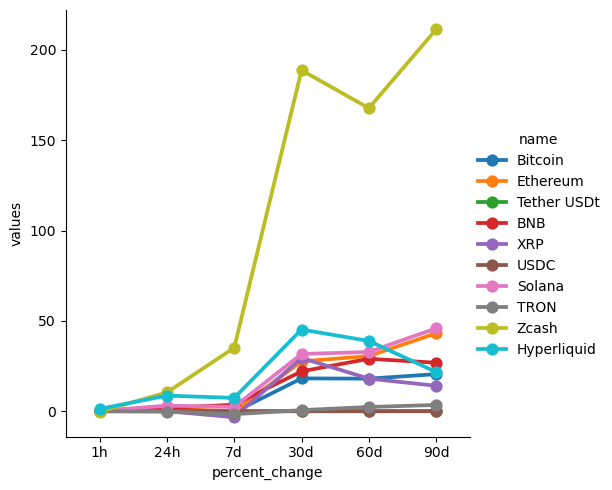

In [59]:
sns.catplot(x='percent_change', y='values', hue='name', data=df7, kind='point')

### Create a DataFrame only with Bitcoin

In [61]:
df8 = df2[['name','quote.USD.price','timestamp']]
df8 = df8.query("name == 'Bitcoin'")
df8

,name,quote.USD.price,timestamp
0,Bitcoin,76355.489,2026-09-17 17:51:53.614323
10,Bitcoin,76336.206,2026-09-17 17:52:53.894940
20,Bitcoin,76309.458,2026-09-17 17:53:54.055835
30,Bitcoin,76309.458,2026-09-17 17:54:54.226699
40,Bitcoin,76282.310,2026-09-17 17:55:54.398127
...,...,...,...
1070,Bitcoin,76336.432,2026-09-17 19:39:17.002345
1080,Bitcoin,76350.700,2026-09-17 19:40:17.173265
1090,Bitcoin,76326.167,2026-09-17 19:41:17.344025
1100,Bitcoin,76303.195,2026-09-17 19:42:17.514967


<Axes: xlabel='timestamp', ylabel='quote.USD.price'>

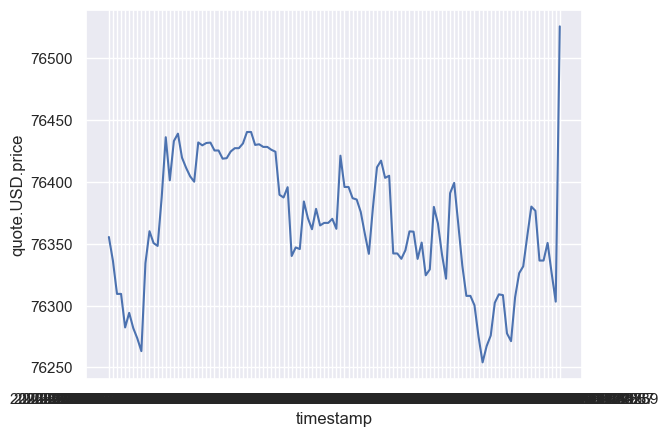

In [65]:
sns.set_theme(style="darkgrid")

sns.lineplot(x='timestamp', y='quote.USD.price', data = df8)
sns.lineplot()

### Prepare the latest observations

In [69]:
# Convert the timestamp column to datetime
df2["timestamp"] = pd.to_datetime(df2["timestamp"])

# Keep the most recent API observation for each cryptocurrency
latest_df = (
    df2.sort_values("timestamp")
      .groupby("name", as_index=False)
      .tail(1)
      .copy()
)

latest_df[[
    "name",
    "symbol",
    "quote.USD.percent_change_24h",
    "quote.USD.market_cap",
    "quote.USD.volume_24h"
]].head()

,name,symbol,quote.USD.percent_change_24h,quote.USD.market_cap,quote.USD.volume_24h
1118,Zcash,ZEC,8.580,24664901616.170,2740912217.285
1110,Bitcoin,BTC,0.313,1537087247006.635,21573600881.254
1111,Ethereum,ETH,1.368,298802129962.422,11473446424.841
1112,Tether USDt,USDT,-0.004,183304601103.881,58978260066.978
1113,BNB,BNB,1.754,98135504498.582,1474167672.510


### Top and bottom 24-hour performers

In [70]:
change_column = "quote.USD.percent_change_24h"

performance_df = (
    latest_df[["name", change_column]]
    .dropna()
    .sort_values(change_column)
)

bottom_5 = performance_df.head(5)
top_5 = performance_df.tail(5)

top_bottom_df = (
    pd.concat([bottom_5, top_5])
      .drop_duplicates(subset="name")
      .sort_values(change_column)
)

top_bottom_df

,name,quote.USD.percent_change_24h
1117,TRON,-0.282
1112,Tether USDt,-0.004
1115,USDC,0.002
1110,Bitcoin,0.313
1114,XRP,0.455
1111,Ethereum,1.368
1113,BNB,1.754
1116,Solana,2.776
1118,Zcash,8.580
1119,Hyperliquid,10.271


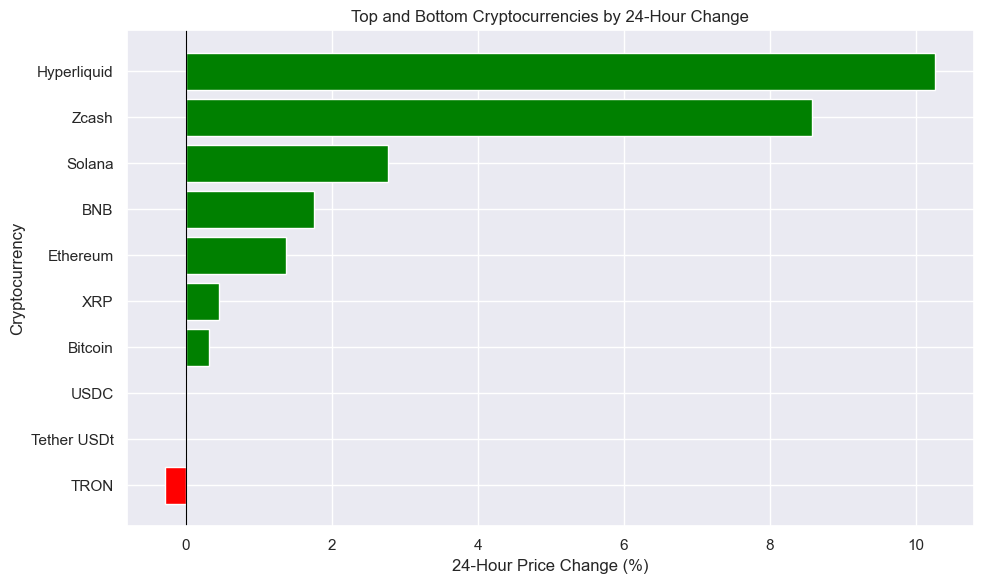

In [71]:
colors = [
    "red" if value < 0 else "green"
    for value in top_bottom_df[change_column]
]

plt.figure(figsize=(10, 6))

plt.barh(
    top_bottom_df["name"],
    top_bottom_df[change_column],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Top and Bottom Cryptocurrencies by 24-Hour Change")
plt.xlabel("24-Hour Price Change (%)")
plt.ylabel("Cryptocurrency")

plt.tight_layout()
plt.show()

In [72]:
best_performer = performance_df.iloc[-1]
worst_performer = performance_df.iloc[0]

print(
    f"Best performer: {best_performer['name']} "
    f"({best_performer[change_column]:.2f}%)"
)

print(
    f"Worst performer: {worst_performer['name']} "
    f"({worst_performer[change_column]:.2f}%)"
)

Best performer: Hyperliquid (10.27%)
Worst performer: TRON (-0.28%)
